# ARD vs Oracle — focused diagnostics

This notebook contains only three diagnostics for the axis-aligned norm problem:

1. projected initial points $z_{\rm init}=A^\top x_{\rm init}$ for each ambient dimension $d$;
2. log improvement from initialization to the final budget;
3. fitted active-coordinate length scales for ARD BO compared with Oracle BO's single effective-space length scale.


## 1. Setup

Set `SAVE_FIGURES = True` to save every generated plot under `DATA_DIR/figures/ard_oracle_diagnostics/`.


In [ ]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data_long3")
CACHE_FILE = DATA_DIR / "cache" / "processed_records.pkl"

# Figure saving
SAVE_FIGURES = False
FIGURE_DIR = DATA_DIR / "figures" / "diagnostics_ard_oracle"
FIGURE_DPI = 200

if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)




In [8]:
if not CACHE_FILE.exists():
    raise FileNotFoundError(
        f"Cache not found: {CACHE_FILE}. Run the main analysis notebook first."
    )

with open(CACHE_FILE, "rb") as f:
    records = pickle.load(f)

# Backward compatibility with older saved terminology.
for r in records:
    if r.get("embedding") == "inclusion":
        r["embedding"] = "aae"

norm_aae = [
    r for r in records
    if r["objective_name"] == "norm"
    and r["embedding"] == "aae"
]

print("Loaded runs:", len(records))
print("Axis-aligned norm runs:", len(norm_aae))
print("Dimensions:", sorted({r["d"] for r in norm_aae}))

Loaded runs: 16800
Axis-aligned norm runs: 400
Dimensions: [2, 5, 10, 20]


## 2. Projected initial points for each $d$

The optimization objective depends only on

$$
z=A^\top x.
$$

For the axis-aligned embedding, this is simply the first two coordinates of $x$. The plot shows all unique initial designs in the effective two-dimensional unit disk.

`X_init` is loaded directly from the saved problem files under `DATA_DIR/problems/`; it does not need to be present in the processed cache.


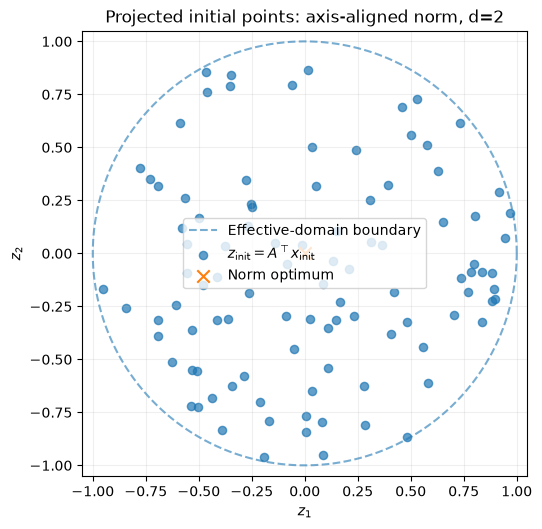

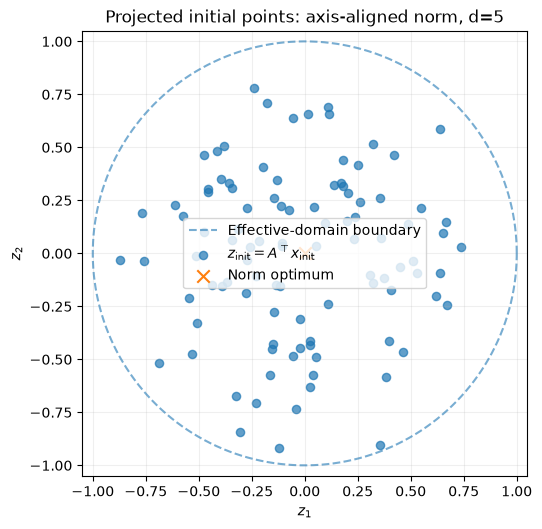

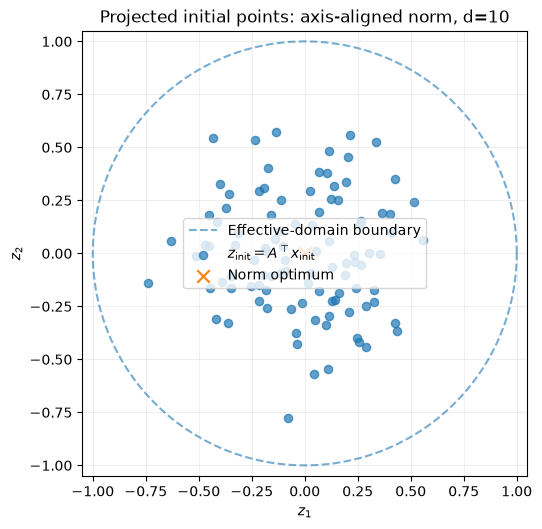

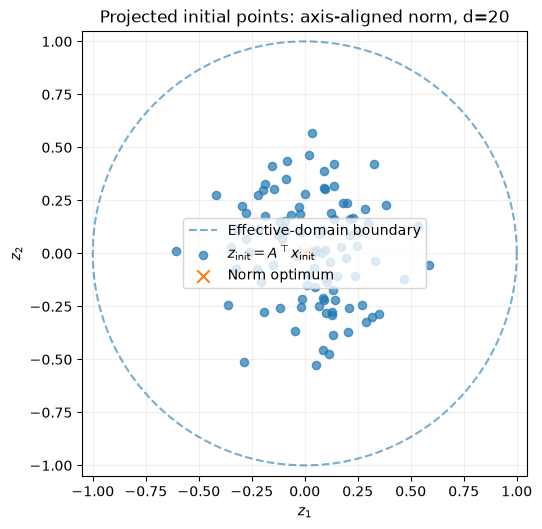

In [9]:
# One record per (d, init_index) is enough because X_init is shared across solvers.
unique_initializations = {}

for r in norm_aae:
    key = (r["d"], r["init_index"])
    if key not in unique_initializations:
        unique_initializations[key] = r


for d in sorted({r["d"] for r in norm_aae}):
    z_sets = []

    for (d_key, init_index), r in unique_initializations.items():
        if d_key != d:
            continue

        # A is already available in the processed record.
        A = np.asarray(r["A"], dtype=float)

        # X_init is problem-level data, so load it directly from the saved
        # problem NPZ instead of duplicating it in the processed cache.
        problem_path = (
            DATA_DIR
            / "problems"
            / f"{r['problem_id']}.npz"
        )

        if not problem_path.exists():
            raise FileNotFoundError(
                f"Problem file not found: {problem_path}"
            )

        with np.load(problem_path) as problem_data:
            X_init = np.asarray(
                problem_data["X_init"],
                dtype=float,
            )

        Z_init = X_init @ A
        z_sets.append(Z_init)

    if not z_sets:
        continue

    Z_all = np.vstack(z_sets)

    theta = np.linspace(0, 2 * np.pi, 400)

    plt.figure(figsize=(5.5, 5.5))

    # Effective feasible domain B_2(1).
    plt.plot(
        np.cos(theta),
        np.sin(theta),
        linestyle="--",
        alpha=0.6,
        label="Effective-domain boundary",
    )

    plt.scatter(
        Z_all[:, 0],
        Z_all[:, 1],
        alpha=0.7,
        s=35,
        label=r"$z_{\rm init}=A^\top x_{\rm init}$",
    )

    # Norm optimum.
    plt.scatter(
        [0],
        [0],
        marker="x",
        s=80,
        label="Norm optimum",
    )

    plt.xlabel("$z_1$")
    plt.ylabel("$z_2$")
    plt.title(
        f"Projected initial points: axis-aligned norm, d={d}"
    )
    plt.xlim(-1.05, 1.05)
    plt.ylim(-1.05, 1.05)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()

    if SAVE_FIGURES:
        plt.savefig(
            FIGURE_DIR / f"projected_initial_points__d{d}.png",
            dpi=FIGURE_DPI,
            bbox_inches="tight",
        )

    plt.show()


## 3. Log improvement from initialization

For each solver run,

$$
I=\log_{10}\left(
\frac{G_{\rm init}+\varepsilon}
{G_{\rm final}+\varepsilon}
\right).
$$

Larger $I$ means that the optimizer reduced the optimality gap by more orders of magnitude after receiving the common initial design.


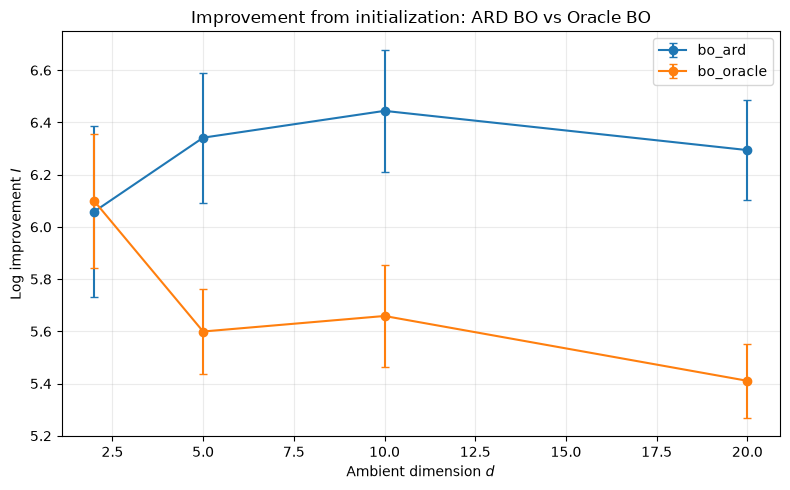

In [10]:
EPSILON = 1e-12

rows = []
for r in norm_aae:
    if r["solver"] not in {"bo_ard", "bo_oracle"}:
        continue

    n_init = len(r["y_init"])
    initial_gap = float(r["gap"][n_init - 1])
    final_gap = float(r["final_gap"])

    rows.append({
        "d": r["d"],
        "init_index": r["init_index"],
        "solver": r["solver"],
        "log_improvement": np.log10(
            (initial_gap + EPSILON) / (final_gap + EPSILON)
        ),
    })

improvement_df = pd.DataFrame(rows)

plt.figure(figsize=(8, 5))

for solver, group in improvement_df.groupby("solver"):
    agg = (
        group.groupby("d")["log_improvement"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )
    se = agg["std"].fillna(0.0) / np.sqrt(agg["count"])

    plt.errorbar(
        agg["d"],
        agg["mean"],
        yerr=se,
        marker="o",
        capsize=3,
        label=solver,
    )

plt.xlabel("Ambient dimension $d$")
plt.ylabel(r"Log improvement $I$")
plt.title("Improvement from initialization: ARD BO vs Oracle BO")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

if SAVE_FIGURES:
    plt.savefig(
        FIGURE_DIR / "log_improvement__ard_vs_oracle.png",
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )

plt.show()


## 4. ARD and Oracle fitted length scales

For the axis-aligned norm problem, ARD has separate fitted length scales for all ambient coordinates. The two active-coordinate length scales are $\ell_1$ and $\ell_2$, while the inactive coordinates are summarized within each run by

$$
\overline{\ell}_{\rm inactive}
=
\frac{1}{d-2}\sum_{j=3}^{d}\ell_j.
$$

Oracle BO fits an isotropic GP in the two-dimensional effective space, so it has a single fitted length scale $\ell_{\rm oracle}$.

For each evaluation number, all four plotted curves are arithmetic means across the available $X_\mathrm{init}$ runs.

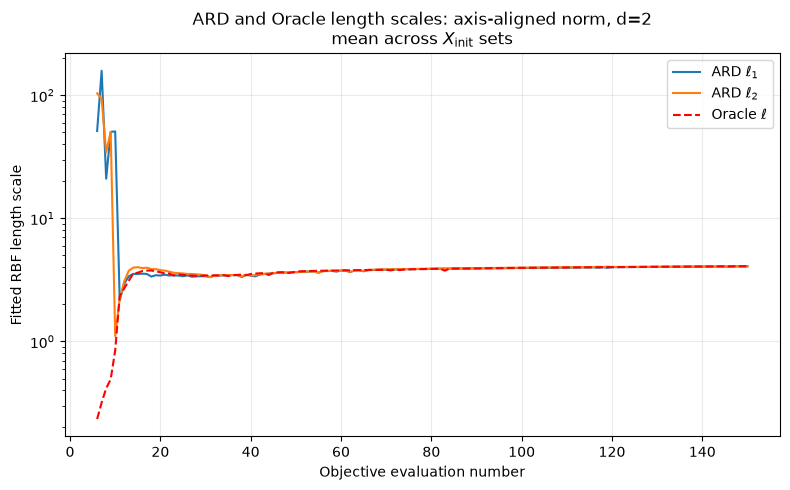

In [11]:
# d = 2: ARD l1, l2 vs Oracle isotropic length scale
d = 2

rows_d2 = []

for r in norm_aae:
    if r["d"] != d or r["solver"] not in {"bo_ard", "bo_oracle"}:
        continue

    n_init = len(r["y_init"])

    for diag in r["diagnostics"]:
        ls = np.asarray(diag["length_scale"], dtype=float)
        evaluation = n_init + int(diag["iteration"])

        if r["solver"] == "bo_ard":
            rows_d2.append({
                "init_index": r["init_index"],
                "evaluation": evaluation,
                "solver": "bo_ard",
                "l1": float(ls[0]),
                "l2": float(ls[1]),
                "oracle_l": np.nan,
            })

        else:  # bo_oracle
            rows_d2.append({
                "init_index": r["init_index"],
                "evaluation": evaluation,
                "solver": "bo_oracle",
                "l1": np.nan,
                "l2": np.nan,
                "oracle_l": float(ls[0]),
            })

d2_df = pd.DataFrame(rows_d2)

ard_d2 = (
    d2_df[d2_df["solver"] == "bo_ard"]
    .groupby("evaluation")
    .agg(
        l1=("l1", "mean"),
        l2=("l2", "mean"),
    )
    .reset_index()
)

oracle_d2 = (
    d2_df[d2_df["solver"] == "bo_oracle"]
    .groupby("evaluation")
    .agg(
        oracle_l=("oracle_l", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(8, 5))

plt.plot(
    ard_d2["evaluation"],
    ard_d2["l1"],
    label=r"ARD $\ell_1$",
)

plt.plot(
    ard_d2["evaluation"],
    ard_d2["l2"],
    label=r"ARD $\ell_2$",
)

plt.plot(
    oracle_d2["evaluation"],
    oracle_d2["oracle_l"],
    color="red",
    linestyle="--",
    label=r"Oracle $\ell$",
)

plt.yscale("log")
plt.xlabel("Objective evaluation number")
plt.ylabel("Fitted RBF length scale")
plt.title(
    "ARD and Oracle length scales: axis-aligned norm, d=2\n"
    r"mean across $X_{\rm init}$ sets"
)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

if SAVE_FIGURES:
    plt.savefig(
        FIGURE_DIR / "length_scales__d2.png",
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )

plt.show()


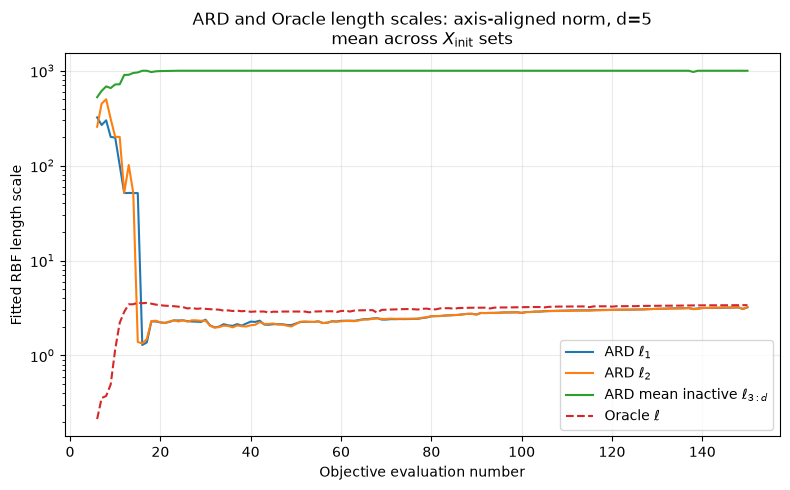

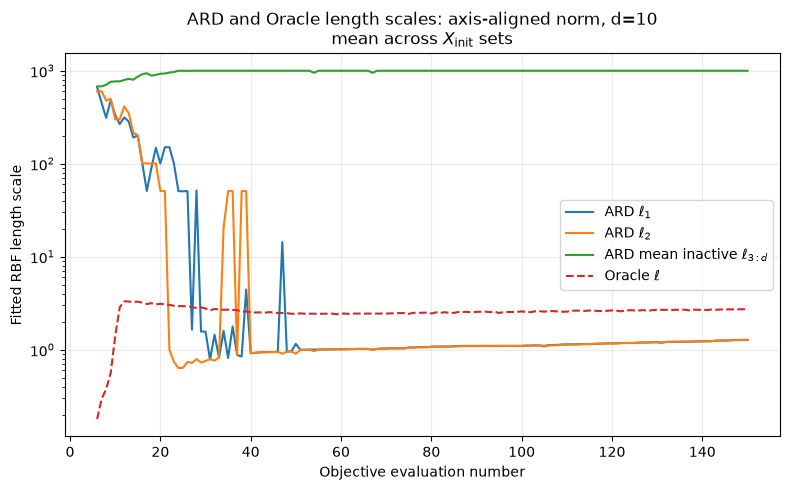

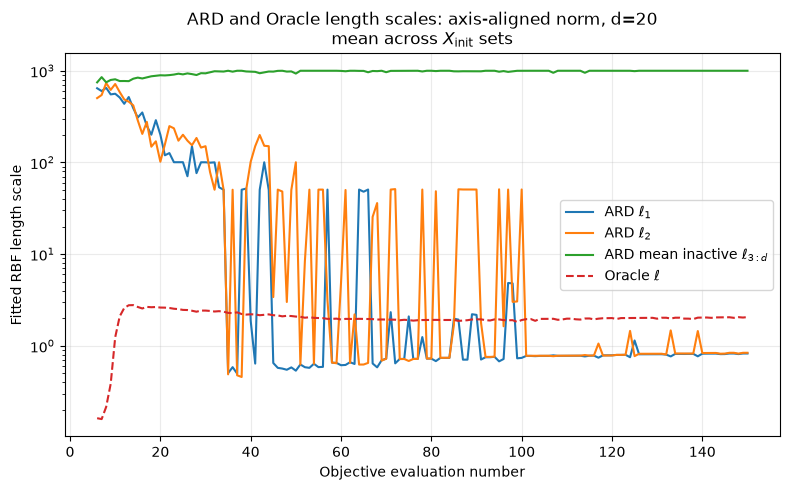

In [12]:
rows = []

for r in norm_aae:
    if r["solver"] not in {"bo_ard", "bo_oracle"} or r["d"] <= 2:
        continue

    n_init = len(r["y_init"])

    for diag in r["diagnostics"]:
        ls = np.asarray(diag["length_scale"], dtype=float)
        evaluation = n_init + int(diag["iteration"])

        if r["solver"] == "bo_ard":
            rows.append({
                "d": r["d"],
                "init_index": r["init_index"],
                "evaluation": evaluation,
                "solver": "bo_ard",
                "l1": float(ls[0]),
                "l2": float(ls[1]),
                "inactive_mean": float(np.mean(ls[2:])),
                "oracle_l": np.nan,
            })

        elif r["solver"] == "bo_oracle":
            rows.append({
                "d": r["d"],
                "init_index": r["init_index"],
                "evaluation": evaluation,
                "solver": "bo_oracle",
                "l1": np.nan,
                "l2": np.nan,
                "inactive_mean": np.nan,
                "oracle_l": float(ls[0]),
            })

lengthscale_df = pd.DataFrame(rows)

for d in sorted(lengthscale_df["d"].unique()):
    sub = lengthscale_df[lengthscale_df["d"] == d]

    ard = (
        sub[sub["solver"] == "bo_ard"]
        .groupby("evaluation")
        .agg(
            l1=("l1", "mean"),
            l2=("l2", "mean"),
            inactive_mean=("inactive_mean", "mean"),
        )
        .reset_index()
    )

    oracle = (
        sub[sub["solver"] == "bo_oracle"]
        .groupby("evaluation")
        .agg(
            oracle_l=("oracle_l", "mean"),
        )
        .reset_index()
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        ard["evaluation"],
        ard["l1"],
        label=r"ARD $\ell_1$",
    )
    plt.plot(
        ard["evaluation"],
        ard["l2"],
        label=r"ARD $\ell_2$",
    )
    plt.plot(
        ard["evaluation"],
        ard["inactive_mean"],
        label=r"ARD mean inactive $\ell_{3:d}$",
    )
    plt.plot(
        oracle["evaluation"],
        oracle["oracle_l"],
        linestyle="--",
        label=r"Oracle $\ell$",
    )

    plt.yscale("log")
    plt.xlabel("Objective evaluation number")
    plt.ylabel("Fitted RBF length scale")
    plt.title(
        f"ARD and Oracle length scales: axis-aligned norm, d={d}\n"
        r"mean across $X_{\rm init}$ sets"
    )
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    if SAVE_FIGURES:
        plt.savefig(
            FIGURE_DIR / f"length_scales__d{d}.png",
            dpi=FIGURE_DPI,
            bbox_inches="tight",
        )

    plt.show()
